# ✅ Notebook de test : vérifiez votre environnement de ML

Bienvenue ! Ce notebook effectue quelques vérifications de base pour s'assurer que votre environnement de machine learning est correctement installé. Il vérifie que vos versions de Python et des bibliothèques correspondent à celles indiquées dans le fichier requirements.txt.

Exécutez simplement les cellules une par une et surveillez les éventuelles erreurs d'assertion (`AssertionError`).


### 🧠 Petit rappel sur les notebooks Jupyter

Les notebooks Jupyter sont un environnement de programmation interactif qui réunit du code, du texte et des visualisations dans un même document. Tout au long de ce cours, vous utiliserez des notebooks pour :

- Lire des consignes et des explications (comme celle-ci !)

- Exécuter et modifier du code Python

- Explorer des données à l'aide de graphiques et de visualisations interactives

👉 Chaque bloc de ce notebook est une **cellule**. Certaines contiennent du **texte**, d'autres du **code**. Cliquez sur une cellule et exécutez-la avec Maj + Entrée ou avec le bouton ▶️ **Run** de la barre d'outils.

### 🐍 Vérifier la version de Python

In [1]:
# Note pédagogique : cette cellule vérifie que le notebook tourne avec la version de Python attendue, avant de contrôler les bibliothèques.

import sys
print("Version de Python :", sys.version)

expected_major, expected_minor = 3, 11

# ✅ On vérifie uniquement la version majeure et mineure (le correctif peut varier)
major, minor = sys.version_info[:2]
assert (major, minor) == (expected_major, expected_minor), \
    f"Python {expected_major}.{expected_minor} attendu, mais {major}.{minor} trouvé."

Python version: 3.11.8 | packaged by conda-forge | (main, Feb 16 2024, 20:49:36) [Clang 16.0.6 ]


### 📦 Vérifier les versions des bibliothèques (d'après requirements.txt)

In [2]:
# Note pédagogique : cette cellule lit la liste des dépendances du projet pour comparer l'environnement aux exigences du cours.

import re

def get_required_versions_from_text(txt):
    required_versions = {}
    for line in txt.splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        if any(op in line for op in ["<", ">", "=", "~"]):
            package = re.split(r"[<>=~]", line)[0]
            if package == "notebook":
                continue  # on ignore les dépendances qui ne servent pas à l'exécution
            match = re.search(r"\d+\.\d+", line)
            if match:
                required_versions[package] = match.group()
    return required_versions

# 📄 Charger le requirements.txt du projet (à la racine, un niveau au-dessus de Labs/)
from pathlib import Path
req_path = next(p for p in [Path("../requirements.txt"), Path("requirements.txt")] if p.exists())
requirements_txt = req_path.read_text()

required_versions = get_required_versions_from_text(requirements_txt)

In [6]:
# Note pédagogique : cette cellule vérifie les versions installées et signale les écarts tôt, avant les exemples plus longs.

import importlib.metadata as metadata

for pkg, required in required_versions.items():
    version = metadata.version(pkg)
    print(f"{pkg}: {version}")
    assert version.startswith(required), f"La version de {pkg} devrait commencer par {required}"

numpy: 2.0.2
pandas: 2.2.3
scipy: 1.16.3
scikit-learn: 1.6.1
tensorflow: 2.18.1
torch: 2.6.0
matplotlib: 3.10.9
plotly: 5.24.1
ipywidgets: 7.7.5


### 📈 Test rapide d'un graphique

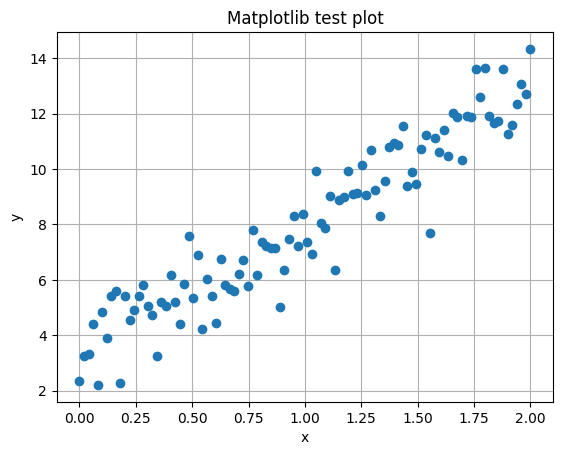

In [7]:
# Note pédagogique : ce petit exemple NumPy + Matplotlib vérifie que le calcul numérique et l'affichage des graphiques fonctionnent.

import numpy as np
import matplotlib.pyplot as plt

# Générer des données synthétiques
x = np.linspace(0, 2, 100)
y = 3 + 5 * x + np.random.randn(100)

plt.plot(x, y, 'o')
plt.title("Graphique de test Matplotlib")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()

### ✅ Tout est bon !

Si vous êtes arrivé ici sans message d'erreur, votre environnement est prêt ! 🎉

Vous pouvez maintenant attaquer les notebooks pratiques : régression, réseaux de neurones, détection d'objets… Amusez-vous bien !